In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.spatial.transform import Rotation
from pathlib import Path
import json, warnings
warnings.filterwarnings('ignore')

try:
    import cv2
    OPENCV = True
    print(f'OpenCV {cv2.__version__}')
except ImportError:
    OPENCV = False
    print('OpenCV not found — will use manual Tsai solver only')

np.set_printoptions(precision=6, suppress=True)

OpenCV 4.8.0


/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [3]:
from pathlib import Path

TF_RECORDS_DIR = Path(
    '/home/pooja/TATRO/TATRO_Program_files/TATARO_FirmwareV1.0'
    '/xarm_ros2/install/tf_recorder/TF_Records'
)

# Set to None to auto-select the most recent CSV
CSV_PATH = Path(
    '/home/pooja/TATRO/TATRO_Program_files/TATARO_FirmwareV1.0'
    '/xarm_ros2/install/tf_recorder/TF_Records/handeye_data_20260610_201226.csv'
)

# Auto-select latest file if CSV_PATH is None
if CSV_PATH is None:
    files = sorted(TF_RECORDS_DIR.glob('handeye_data_*.csv'))
    if not files:
        raise FileNotFoundError(f'No CSV found in {TF_RECORDS_DIR}')
    CSV_PATH = files[-1]

print(f'Using: {CSV_PATH}')

Using: /home/pooja/TATRO/TATRO_Program_files/TATARO_FirmwareV1.0/xarm_ros2/install/tf_recorder/TF_Records/handeye_data_20260610_201226.csv


In [10]:
df = pd.read_csv(CSV_PATH)
N  = len(df)
print(f'Samples  : {N}')
print(f'Columns  : {len(df.columns)}')
print(f'ID range : {df.sample_id.min()} → {df.sample_id.max()}')


for pfx in ['lb_l6','lb_eef','lb_tcp','cam_marker']:
    bad = ((df[f'{pfx}_T30'] != 0) | (df[f'{pfx}_T31'] != 0) |
           (df[f'{pfx}_T32'] != 0) | (df[f'{pfx}_T33'] != 1)).sum()
    status = 'OK' if bad == 0 else f'WARNING {bad} bad rows'
    print(f'  {pfx:<14} bottom-row check: {status}')

df.head(2)

Samples  : 21
Columns  : 95
ID range : 0 → 20
  lb_l6          bottom-row check: OK
  lb_eef         bottom-row check: OK
  lb_tcp         bottom-row check: OK
  cam_marker     bottom-row check: OK


,sample_id,timestamp_sec,timestamp_nanosec,lb_l6_x,lb_l6_y,lb_l6_z,lb_l6_qx,lb_l6_qy,lb_l6_qz,lb_l6_qw,...,cam_marker_T12,cam_marker_T13,cam_marker_T20,cam_marker_T21,cam_marker_T22,cam_marker_T23,cam_marker_T30,cam_marker_T31,cam_marker_T32,cam_marker_T33
0,0,1781102617,601967207,0.234941,-0.000545,0.547038,0.989818,-0.029482,0.139248,0.000283,...,0.199418,0.038894,-0.198308,0.023069,-0.979868,0.555138,0.0,0.0,0.0,1.0
1,1,1781102641,421681535,0.289441,-0.211600,0.413601,0.967312,0.123226,0.162279,-0.150961,...,0.307932,-0.010272,-0.209166,-0.400475,-0.892115,0.466906,0.0,0.0,0.0,1.0


In [6]:
df = pd.read_csv(CSV_PATH, nrows=0)
print(df.columns)

Index(['sample_id', 'timestamp_sec', 'timestamp_nanosec', 'lb_l6_x', 'lb_l6_y',
       'lb_l6_z', 'lb_l6_qx', 'lb_l6_qy', 'lb_l6_qz', 'lb_l6_qw', 'lb_l6_T00',
       'lb_l6_T01', 'lb_l6_T02', 'lb_l6_T03', 'lb_l6_T10', 'lb_l6_T11',
       'lb_l6_T12', 'lb_l6_T13', 'lb_l6_T20', 'lb_l6_T21', 'lb_l6_T22',
       'lb_l6_T23', 'lb_l6_T30', 'lb_l6_T31', 'lb_l6_T32', 'lb_l6_T33',
       'lb_eef_x', 'lb_eef_y', 'lb_eef_z', 'lb_eef_qx', 'lb_eef_qy',
       'lb_eef_qz', 'lb_eef_qw', 'lb_eef_T00', 'lb_eef_T01', 'lb_eef_T02',
       'lb_eef_T03', 'lb_eef_T10', 'lb_eef_T11', 'lb_eef_T12', 'lb_eef_T13',
       'lb_eef_T20', 'lb_eef_T21', 'lb_eef_T22', 'lb_eef_T23', 'lb_eef_T30',
       'lb_eef_T31', 'lb_eef_T32', 'lb_eef_T33', 'lb_tcp_x', 'lb_tcp_y',
       'lb_tcp_z', 'lb_tcp_qx', 'lb_tcp_qy', 'lb_tcp_qz', 'lb_tcp_qw',
       'lb_tcp_T00', 'lb_tcp_T01', 'lb_tcp_T02', 'lb_tcp_T03', 'lb_tcp_T10',
       'lb_tcp_T11', 'lb_tcp_T12', 'lb_tcp_T13', 'lb_tcp_T20', 'lb_tcp_T21',
       'lb_tcp_T22', 'lb_tcp_

In [ ]:
#OpenCV Hand-Eye Calib

#For link_tcp

R_gripper2base = []
t_gripper2base = []
R_target2cam = []
t_target2cam = []

for _, row in df.iterrows():

    Tg = np.array([
        [row.lb_tcp_T00, row.lb_tcp_T01, row.lb_tcp_T02, row.lb_tcp_T03],
        [row.lb_tcp_T10, row.lb_tcp_T11, row.lb_tcp_T12, row.lb_tcp_T13],
        [row.lb_tcp_T20, row.lb_tcp_T21, row.lb_tcp_T22, row.lb_tcp_T23],
        [row.lb_tcp_T30, row.lb_tcp_T31, row.lb_tcp_T32, row.lb_tcp_T33]
    ])

    Tc = np.array([
        [row.cam_marker_T00, row.cam_marker_T01, row.cam_marker_T02, row.cam_marker_T03],
        [row.cam_marker_T10, row.cam_marker_T11, row.cam_marker_T12, row.cam_marker_T13],
        [row.cam_marker_T20, row.cam_marker_T21, row.cam_marker_T22, row.cam_marker_T23],
        [row.cam_marker_T30, row.cam_marker_T31, row.cam_marker_T32, row.cam_marker_T33]
    ])

    R_gripper2base.append(Tg[:3, :3])
    t_gripper2base.append(Tg[:3, 3])

    R_target2cam.append(Tc[:3, :3])
    t_target2cam.append(Tc[:3, 3])


    print(len(R_gripper2base))
    print(len(t_gripper2base))
    print(len(R_target2cam))
    print(len(t_target2cam))

In [14]:
R_cam2tcp, t_cam2tcp = cv2.calibrateHandEye(
    R_gripper2base,
    t_gripper2base,
    R_target2cam,
    t_target2cam,
    method=cv2.CALIB_HAND_EYE_TSAI
)


print("Rotation:")
print(R_cam2tcp)

print("\nTranslation:")
print(t_cam2tcp)

Rotation:
[[ 0.071277  0.995531  0.061946]
 [-0.997142  0.072676 -0.020627]
 [-0.025037 -0.060299  0.997866]]

Translation:
[[ 0.066196]
 [ 0.032414]
 [-0.056499]]


In [ ]:
#Homogeneous TM
T_tcp_camera = np.eye(4)
T_tcp_camera[:3, :3] = R_cam2tcp
T_tcp_camera[:3, 3] = t_cam2tcp.flatten()

print(T_tcp_camera)

[[ 0.071277  0.995531  0.061946  0.066196]
 [-0.997142  0.072676 -0.020627  0.032414]
 [-0.025037 -0.060299  0.997866 -0.056499]
 [ 0.        0.        0.        1.      ]]


In [34]:
from scipy.spatial.transform import Rotation as R
marker_positions = []
marker_rotations = []

quats = []
for _, row in df.iterrows():

    T_base_tcp = np.array([
        [row.lb_tcp_T00,row.lb_tcp_T01,row.lb_tcp_T02,row.lb_tcp_T03],
        [row.lb_tcp_T10,row.lb_tcp_T11,row.lb_tcp_T12,row.lb_tcp_T13],
        [row.lb_tcp_T20,row.lb_tcp_T21,row.lb_tcp_T22,row.lb_tcp_T23],
        [row.lb_tcp_T30,row.lb_tcp_T31,row.lb_tcp_T32,row.lb_tcp_T33]
    ])

    T_cam_marker = np.array([
        [row.cam_marker_T00,row.cam_marker_T01,row.cam_marker_T02,row.cam_marker_T03],
        [row.cam_marker_T10,row.cam_marker_T11,row.cam_marker_T12,row.cam_marker_T13],
        [row.cam_marker_T20,row.cam_marker_T21,row.cam_marker_T22,row.cam_marker_T23],
        [row.cam_marker_T30,row.cam_marker_T31,row.cam_marker_T32,row.cam_marker_T33]
    ])

    T_base_marker = (
        T_base_tcp @
        T_tcp_camera @
        T_cam_marker
    )

    marker_positions.append(T_base_marker[:3,3])
    marker_rotations.append(
        R.from_matrix(T_base_marker[:3, :3])
    )    
    q = R.from_matrix(T_base_marker[:3,:3]).as_quat()  # x,y,z,w
    quats.append(q)

quats = np.array(quats)

marker_positions = np.array(marker_positions)



print(marker_positions.mean(axis=0))
print(marker_positions.std(axis=0))

[ 0.488048  0.004273 -0.001516]
[0.026204 0.035233 0.018372]


In [33]:
rot_mats = np.array([r.as_matrix() for r in marker_rotations])

R_mean = R.from_matrix(rot_mats.mean(axis=0))
angles = []

for R_i in marker_rotations:

    R_err = R_mean.inv() * R_i

    angle_deg = np.degrees(
        np.linalg.norm(R_err.as_rotvec())
    )

    angles.append(angle_deg)

angles = np.array(angles)

print("Mean angular error:", angles.mean(), "deg")
print("Max angular error :", angles.max(), "deg")
print("Std angular error :", angles.std(), "deg")

Mean angular error: 4.323977995691903 deg
Max angular error : 7.151489137648504 deg
Std angular error : 1.4640835254307412 deg


In [38]:
eulers = np.array([
    rot.as_euler('xyz', degrees=True)
    for rot in marker_rotations
])

print("Shape:", eulers.shape)

Shape: (21, 3)


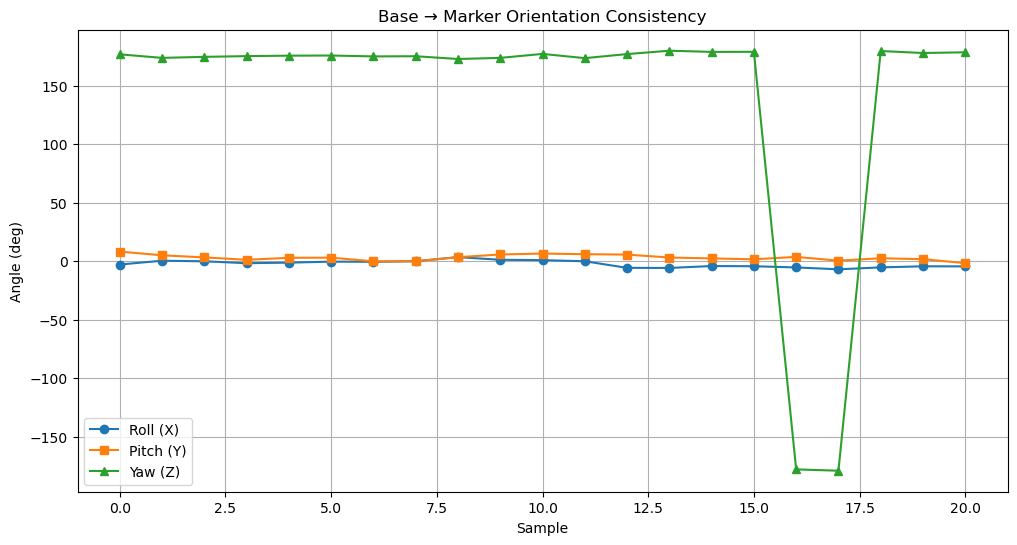

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

plt.plot(eulers[:,0], 'o-', label='Roll (X)')
plt.plot(eulers[:,1], 's-', label='Pitch (Y)')
plt.plot(eulers[:,2], '^-', label='Yaw (Z)')

plt.xlabel('Sample')
plt.ylabel('Angle (deg)')
plt.title('Base → Marker Orientation Consistency')
plt.grid(True)
plt.legend()

plt.show()

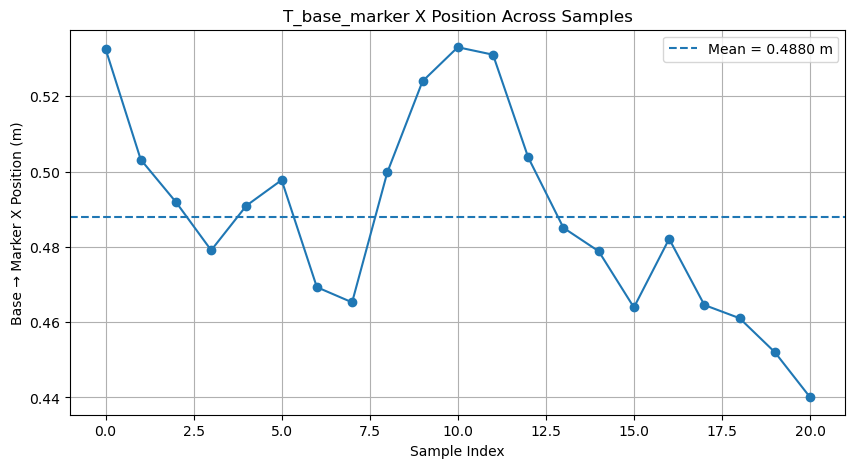

In [23]:
import matplotlib.pyplot as plt
import numpy as np

x_positions = marker_positions[:, 0]

plt.figure(figsize=(10, 5))
plt.plot(range(len(x_positions)), x_positions, marker='o')
plt.xlabel('Sample Index')
plt.ylabel('Base → Marker X Position (m)')
plt.title('T_base_marker X Position Across Samples')
plt.grid(True)

plt.axhline(
    np.mean(x_positions),
    linestyle='--',
    label=f'Mean = {np.mean(x_positions):.4f} m'
)

plt.legend()
plt.show()

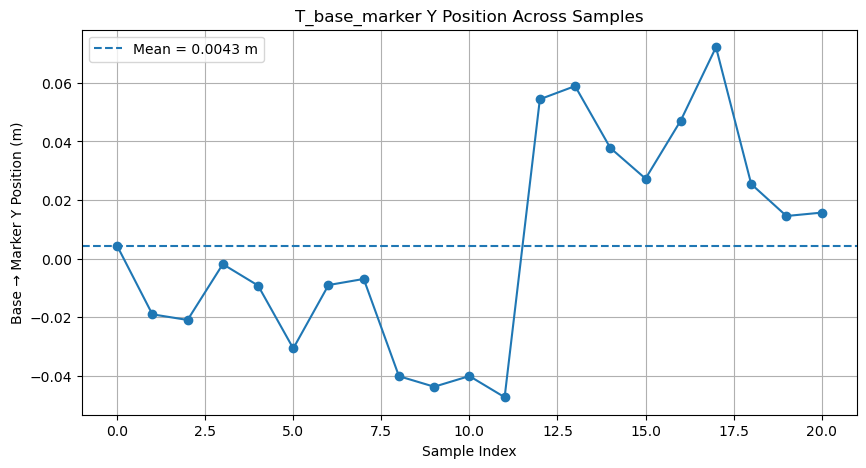

In [24]:
import matplotlib.pyplot as plt
import numpy as np

y_positions = marker_positions[:, 1]

plt.figure(figsize=(10, 5))
plt.plot(range(len(y_positions)), y_positions, marker='o')
plt.xlabel('Sample Index')
plt.ylabel('Base → Marker Y Position (m)')
plt.title('T_base_marker Y Position Across Samples')
plt.grid(True)

plt.axhline(
    np.mean(y_positions),
    linestyle='--',
    label=f'Mean = {np.mean(y_positions):.4f} m'
)

plt.legend()
plt.show()

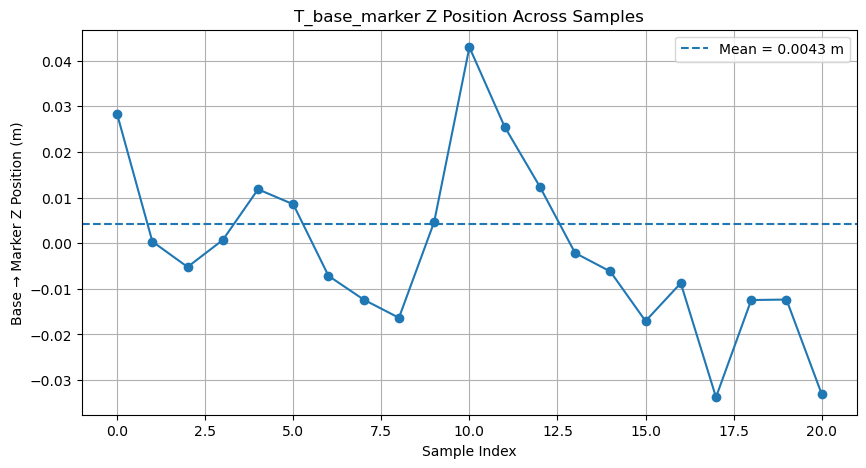

In [25]:
import matplotlib.pyplot as plt
import numpy as np

z_positions = marker_positions[:, 2]

plt.figure(figsize=(10, 5))
plt.plot(range(len(z_positions)), z_positions, marker='o')
plt.xlabel('Sample Index')
plt.ylabel('Base → Marker Z Position (m)')
plt.title('T_base_marker Z Position Across Samples')
plt.grid(True)

plt.axhline(
    np.mean(y_positions),
    linestyle='--',
    label=f'Mean = {np.mean(y_positions):.4f} m'
)

plt.legend()
plt.show()

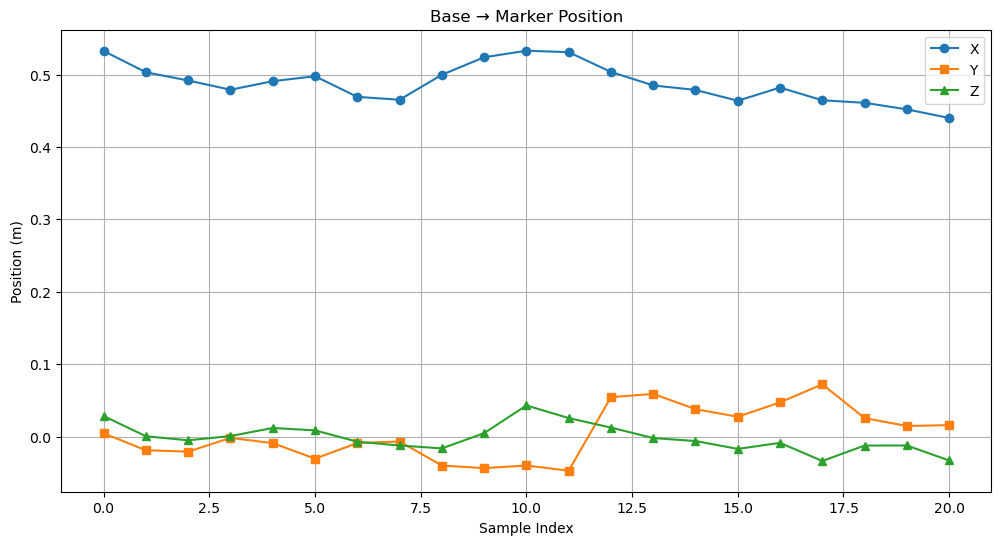

In [29]:
plt.figure(figsize=(12,6))

plt.plot(marker_positions[:,0], 'o-', label='X')
plt.plot(marker_positions[:,1], 's-', label='Y')
plt.plot(marker_positions[:,2], '^-', label='Z')

plt.xlabel('Sample Index')
plt.ylabel('Position (m)')
plt.title('Base → Marker Position')
plt.grid(True)
plt.legend()
plt.show()

In [17]:
#OpenCV Hand-Eye Calib

R_gripper2base = []
t_gripper2base = []

R_target2cam = []
t_target2cam = []

for _, row in df.iterrows():

    Tg = np.array([
        [row.lb_eef_T00, row.lb_eef_T01, row.lb_eef_T02, row.lb_eef_T03],
        [row.lb_eef_T10, row.lb_eef_T11, row.lb_eef_T12, row.lb_eef_T13],
        [row.lb_eef_T20, row.lb_eef_T21, row.lb_eef_T22, row.lb_eef_T23],
        [row.lb_eef_T30, row.lb_eef_T31, row.lb_eef_T32, row.lb_eef_T33]
    ])

    Tc = np.array([
        [row.cam_marker_T00, row.cam_marker_T01, row.cam_marker_T02, row.cam_marker_T03],
        [row.cam_marker_T10, row.cam_marker_T11, row.cam_marker_T12, row.cam_marker_T13],
        [row.cam_marker_T20, row.cam_marker_T21, row.cam_marker_T22, row.cam_marker_T23],
        [row.cam_marker_T30, row.cam_marker_T31, row.cam_marker_T32, row.cam_marker_T33]
    ])

    R_gripper2base.append(Tg[:3, :3])
    # print("Num poses:", len(R_gripper2base))
    t_gripper2base.append(Tg[:3, 3])
    # print("Num poses:", len(t_gripper2base))

    R_target2cam.append(Tc[:3, :3])
    t_target2cam.append(Tc[:3, 3])


    print(len(R_gripper2base))
    print(len(t_gripper2base))
    print(len(R_target2cam))
    print(len(t_target2cam))

1
1
1
1
2
2
2
2
3
3
3
3
4
4
4
4
5
5
5
5
6
6
6
6
7
7
7
7
8
8
8
8
9
9
9
9
10
10
10
10
11
11
11
11
12
12
12
12
13
13
13
13
14
14
14
14
15
15
15
15
16
16
16
16
17
17
17
17
18
18
18
18
19
19
19
19
20
20
20
20
21
21
21
21


In [19]:
R_cam2eef, t_cam2eef = cv2.calibrateHandEye(
    R_gripper2base,
    t_gripper2base,
    R_target2cam,
    t_target2cam,
    method=cv2.CALIB_HAND_EYE_TSAI
)


print("Rotation:")
print(R_cam2eef)

print("\nTranslation:")
print(t_cam2eef)

Rotation:
[[ 0.071277  0.995531  0.061946]
 [-0.997142  0.072676 -0.020627]
 [-0.025037 -0.060299  0.997866]]

Translation:
[[0.066196]
 [0.032414]
 [0.030101]]


In [21]:
T_eef_camera = np.eye(4)
T_eef_camera[:3, :3] = R_cam2tcp
T_eef_camera[:3, 3] = t_cam2tcp.flatten()

print(T_eef_camera)

[[ 0.071277  0.995531  0.061946  0.066196]
 [-0.997142  0.072676 -0.020627  0.032414]
 [-0.025037 -0.060299  0.997866  0.030101]
 [ 0.        0.        0.        1.      ]]


In [22]:
marker_positions = []

for _, row in df.iterrows():

    T_base_eef = np.array([
        [row.lb_eef_T00,row.lb_eef_T01,row.lb_eef_T02,row.lb_eef_T03],
        [row.lb_eef_T10,row.lb_eef_T11,row.lb_eef_T12,row.lb_eef_T13],
        [row.lb_eef_T20,row.lb_eef_T21,row.lb_eef_T22,row.lb_eef_T23],
        [row.lb_eef_T30,row.lb_eef_T31,row.lb_eef_T32,row.lb_eef_T33]
    ])

    T_cam_marker = np.array([
        [row.cam_marker_T00,row.cam_marker_T01,row.cam_marker_T02,row.cam_marker_T03],
        [row.cam_marker_T10,row.cam_marker_T11,row.cam_marker_T12,row.cam_marker_T13],
        [row.cam_marker_T20,row.cam_marker_T21,row.cam_marker_T22,row.cam_marker_T23],
        [row.cam_marker_T30,row.cam_marker_T31,row.cam_marker_T32,row.cam_marker_T33]
    ])

    T_base_marker = (
        T_base_eef @
        T_eef_camera @
        T_cam_marker
    )

    marker_positions.append(T_base_marker[:3,3])

marker_positions = np.array(marker_positions)

print(marker_positions.mean(axis=0))
print(marker_positions.std(axis=0))

[ 0.488048  0.004273 -0.001516]
[0.026204 0.035233 0.018372]
